In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [10]:
# TASK 01
np.random.seed(42)

YearsOfExperience = np.random.randint(2, 21, size=500)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)

noise = np.random.normal(0, 10000, size=500)

Salary = intercept + slope * YearsOfExperience + noise

df = pd.DataFrame({
    'YearsOfExperience': YearsOfExperience,
    'Salary': Salary
})

print(df.head())

print(df.shape)

   YearsOfExperience         Salary
0                  8  115037.780010
1                 16  182309.972927
2                 12  156442.408989
3                  9  144753.562169
4                  8  130798.818454
(500, 2)


In [11]:
# TASK 02
print(df.shape)

print(df.describe())

print(df.isnull().sum())

print(df['YearsOfExperience'].corr(df['Salary']))

(500, 2)
       YearsOfExperience         Salary
count         500.000000     500.000000
mean           10.616000  142570.011096
std             5.662922   44935.263058
min             2.000000   54881.134555
25%             5.750000  104426.300731
50%            10.000000  139865.032545
75%            16.000000  182341.125962
max            20.000000  241879.376204
YearsOfExperience    0
Salary               0
dtype: int64
0.975058457607618


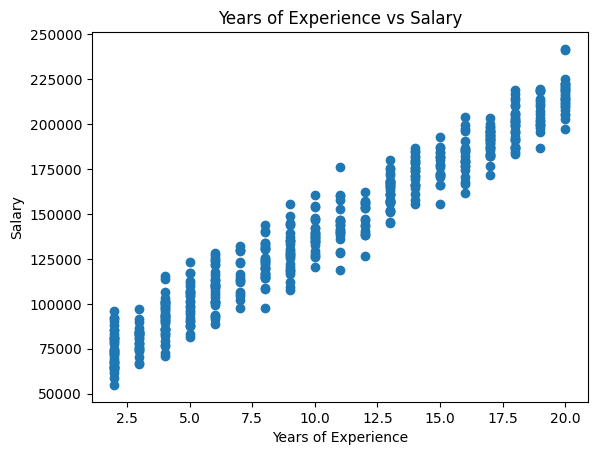

In [12]:
# TASK 03
plt.scatter(df['YearsOfExperience'], df['Salary'])

plt.xlabel('Years of Experience')
plt.ylabel('Salary')

plt.title('Years of Experience vs Salary')

plt.show()

In [13]:
# TASK 04
X = df[['YearsOfExperience']]
y = df['Salary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


In [14]:
# TASK 05
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Slope:", lr_model.coef_[0])
print("Intercept:", lr_model.intercept_)

print("Training R2:", lr_model.score(X_train, y_train))
print("Test R2:", lr_model.score(X_test, y_test))

Slope: 7696.612923052044
Intercept: 60961.340880280564
Training R2: 0.9488372177019488
Test R2: 0.9573704756930141


In [15]:
# TASK 06
y_pred = lr_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

results = pd.DataFrame({
    'Actual Salary': y_test,
    'Predicted Salary': y_pred
})

print(results.head())

MAE: 7905.114728709239
MSE: 93933277.37947103
RMSE: 9691.918147584152
R2: 0.9573704756930141
     Actual Salary  Predicted Salary
361  123631.230350     107141.018419
73   139775.630647     122534.244265
374   93184.812446     107141.018419
155  166740.803478     161017.308880
104  174587.183981     184107.147649


In [16]:
# TASK 07
baseline_prediction = y_train.mean()

y_baseline = np.full(len(y_test), baseline_prediction)

baseline_mae = mean_absolute_error(y_test, y_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_baseline))

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

print("Linear Regression MAE:", mae)
print("Linear Regression RMSE:", rmse)

Baseline MAE: 40444.95787424255
Baseline RMSE: 46953.769510036946
Linear Regression MAE: 7905.114728709239
Linear Regression RMSE: 9691.918147584152


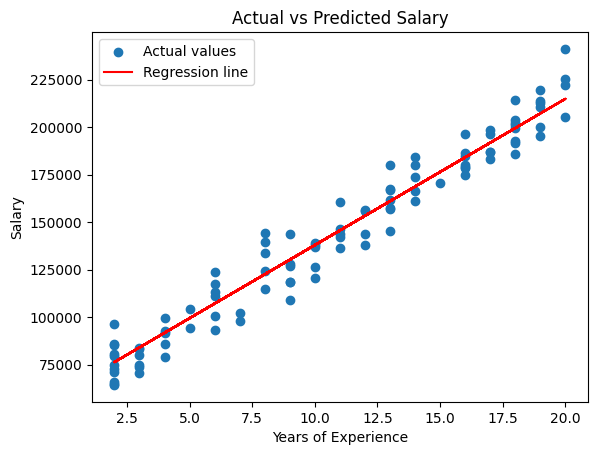

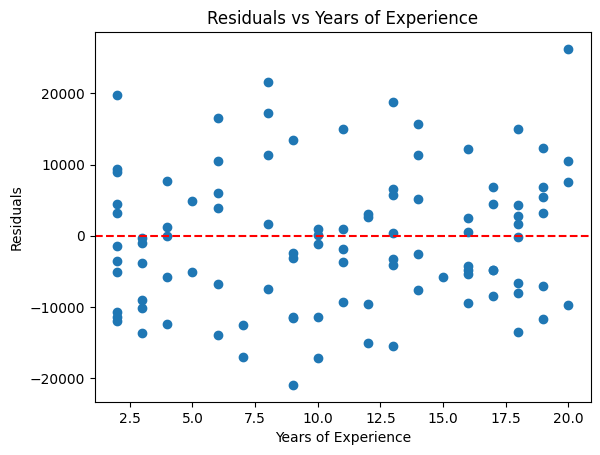

In [17]:
# TASK 08
residuals = y_test - y_pred

plt.scatter(X_test, y_test, label='Actual values')
plt.plot(X_test, y_pred, color='red', label='Regression line')

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Actual vs Predicted Salary')
plt.legend()
plt.show()

plt.scatter(X_test, residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Years of Experience')
plt.ylabel('Residuals')
plt.title('Residuals vs Years of Experience')
plt.show()

In [18]:
# TASK 09
X_new = pd.DataFrame({
    'YearsOfExperience': [5, 10, 15]
})

new_predictions = lr_model.predict(X_new)

new_results = pd.DataFrame({
    'YearsOfExperience': [5, 10, 15],
    'Predicted Salary': new_predictions
})

print(new_results)

   YearsOfExperience  Predicted Salary
0                  5      99444.405496
1                 10     137927.470111
2                 15     176410.534726


In [31]:
# TASK 10

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Original X_train:")
print(X_train.head())

print("\nScaled X_train:")
print(X_train_scaled[:5])

print("\nScaled X_test:")
print(X_test_scaled[:5])

Original X_train:
     YearsOfExperience
249                 17
433                  8
19                  11
322                  2
332                  4

Scaled X_train:
[[ 1.14441709]
 [-0.45865743]
 [ 0.07570074]
 [-1.52737378]
 [-1.171135  ]]

Scaled X_test:
[[-0.81489621]
 [-0.45865743]
 [-0.81489621]
 [ 0.43193952]
 [ 0.9662977 ]]


In [25]:
 # TASK 11
ridge_10 = Ridge(alpha=10)
ridge_100 = Ridge(alpha=100)

ridge_10.fit(X_train_scaled, y_train)
ridge_100.fit(X_train_scaled, y_train)

ridge_10_pred = ridge_10.predict(X_test_scaled)
ridge_100_pred = ridge_100.predict(X_test_scaled)

print("Ridge alpha=10")
print("Coefficient:", ridge_10.coef_[0])
print("MAE:", mean_absolute_error(y_test, ridge_10_pred))
print("R2:", r2_score(y_test, ridge_10_pred))

print("\nRidge alpha=100")
print("Coefficient:", ridge_100.coef_[0])
print("MAE:", mean_absolute_error(y_test, ridge_100_pred))
print("R2:", r2_score(y_test, ridge_100_pred))

Ridge alpha=10
Coefficient: 42156.50310768269
MAE: 8084.461347657729
R2: 0.9557273924644272

Ridge alpha=100
Coefficient: 34568.33254829981
MAE: 11308.369993936485
R2: 0.9118378157040179


In [26]:
# TASK 12
lasso_1000 = Lasso(alpha=1000, max_iter=20000)
lasso_10000 = Lasso(alpha=10000, max_iter=20000)
lasso_50000 = Lasso(alpha=50000, max_iter=20000)

lasso_1000.fit(X_train_scaled, y_train)
lasso_10000.fit(X_train_scaled, y_train)
lasso_50000.fit(X_train_scaled, y_train)

lasso_1000_pred = lasso_1000.predict(X_test_scaled)
lasso_10000_pred = lasso_10000.predict(X_test_scaled)
lasso_50000_pred = lasso_50000.predict(X_test_scaled)

print("Lasso alpha=1000")
print("Coefficient:", lasso_1000.coef_[0])
print("MAE:", mean_absolute_error(y_test, lasso_1000_pred))
print("R2:", r2_score(y_test, lasso_1000_pred))

print("\nLasso alpha=10000")
print("Coefficient:", lasso_10000.coef_[0])
print("MAE:", mean_absolute_error(y_test, lasso_10000_pred))
print("R2:", r2_score(y_test, lasso_10000_pred))

print("\nLasso alpha=50000")
print("Coefficient:", lasso_50000.coef_[0])
print("MAE:", mean_absolute_error(y_test, lasso_50000_pred))
print("R2:", r2_score(y_test, lasso_50000_pred))

Lasso alpha=1000
Coefficient: 42210.415685374755
MAE: 8074.651462959587
R2: 0.9558378005043271

Lasso alpha=10000
Coefficient: 33210.41568537476
MAE: 12287.962687167314
R2: 0.8980447982632193

Lasso alpha=50000
Coefficient: 0.0
MAE: 40444.95787424255
R2: -0.0005342009730120445


In [33]:
# TASK 13
ridge_10_pred = ridge_10.predict ( X_test_scaled )
lasso_1000_pred = lasso_1000.predict ( X_test_scaled )

comparison = pd.DataFrame ({ 'Model' : [ 'Mean Baseline' , 'Linear Regression' , 'Ridge (alpha=10)' , 'Lasso (alpha=1000)' ],


    'MAE' : [
        baseline_mae ,
        mean_absolute_error ( y_test ,  y_pred ),
        mean_absolute_error ( y_test ,  ridge_10_pred ),
        mean_absolute_error ( y_test ,  lasso_1000_pred ) ],


    'RMSE' : [
        baseline_rmse ,
        np.sqrt ( mean_squared_error ( y_test ,  y_pred )),
        np.sqrt ( mean_squared_error ( y_test ,  ridge_10_pred )),
        np.sqrt ( mean_squared_error ( y_test ,  lasso_1000_pred )) ],


    'R2' : [
        r2_score ( y_test ,  y_baseline ),
        r2_score ( y_test ,  y_pred ),
        r2_score ( y_test ,  ridge_10_pred ),
        r2_score ( y_test ,  lasso_1000_pred ) ] })



print(comparison.round(2))

                Model       MAE      RMSE    R2
0       Mean Baseline  40444.96  46953.77 -0.00
1   Linear Regression   7905.11   9691.92  0.96
2    Ridge (alpha=10)   8084.46   9876.93  0.96
3  Lasso (alpha=1000)   8074.65   9864.61  0.96
